In [48]:
import numpy as np
import scipy
import pandas as pd
import pathlib
import gala.coordinates as gc

import astropy
from astropy.table import Table,vstack,hstack,join
import astropy.coordinates as coord
import astropy.units as u

import matplotlib as mpl
import matplotlib.pyplot as plt
import cmasher as cmr


/Users/Tavangar/Work/virtual_envs/.stream-env/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [49]:
data_dir = pathlib.Path('/Users/Tavangar/Work/gd1-dr3/data/dataset_data')

In [430]:

gaia_dr3_column_subset = ['source_id', 'ra', 'dec', 'parallax', 'pmra', 'pmdec', 'pmra_error', 
                          'pmdec_error', 'rv_gaia', 'rv_error_gaia', 
                          'phot_g_mean_mag', 'phot_g_mean_flux_over_error', 
                          'phot_bp_mean_mag', 'phot_bp_mean_flux_over_error', 
                          'phot_rp_mean_mag', 'phot_rp_mean_flux_over_error', 
                          'ruwe', 'ra_parallax_corr', 'ra_pmra_corr', 'ra_pmdec_corr', 
                          'dec_parallax_corr', 'dec_pmra_corr', 'dec_pmdec_corr', 
                          'parallax_pmra_corr', 'parallax_pmdec_corr', 'pmra_pmdec_corr', 
                          'phi1', 'phi2', 'pm_phi1_cosphi2_unrefl', 'pm_phi2_unrefl', 'pm1_error', 'pm2_error']
ps1_column_subset = ['gaia_source_id', 'ra_ps1', 'dec_ps1', 'nDetections', 'ng', 'nr', 'ni', 'nz', 'ny', 
                     'gMeanPSFMag', 'rMeanPSFMag', 'iMeanPSFMag', 'zMeanPSFMag', 'yMeanPSFMag', 
                     'gMeanPSFMagErr', 'rMeanPSFMagErr', 'iMeanPSFMagErr', 'zMeanPSFMagErr', 'yMeanPSFMagErr', 
                     'gMeanKronMag', 'rMeanKronMag', 'iMeanKronMag', 'zMeanKronMag', 'yMeanKronMag', 
                     'gMeanKronMagErr', 'rMeanKronMagErr', 'iMeanKronMagErr', 'zMeanKronMagErr', 'yMeanKronMagErr']
# only taking radial velocities for now. Can look at metallicities once I have member probabilities
desi_column_subset = ['gaia_source_id','rv_desi', 'rv_error_desi']
apogee_column_subset = ['gaia_source_id', 'rv_apogee', 'rv_error_apogee']

In [196]:
print('Loading Gaia DR3 data')
gaia_dr3_data = Table.read(data_dir / 'gd1-dr3-all.fits')
gaia_dr3_data.rename_column('radial_velocity', 'rv_gaia')
gaia_dr3_data.rename_column('radial_velocity_error', 'rv_error_gaia')
gaia_dr3_icrs = coord.SkyCoord(ra=gaia_dr3_data['ra']*u.deg, dec=gaia_dr3_data['dec']*u.deg, frame='icrs').flatten()
gaia_dr3_gd1_frame = gaia_dr3_icrs.transform_to(gc.GD1Koposov10())
gaia_dr3_data = gaia_dr3_data[(gaia_dr3_gd1_frame.phi1.degree>-100) & (gaia_dr3_gd1_frame.phi1.degree<20) & 
                             (gaia_dr3_gd1_frame.phi2.degree>-8) & (gaia_dr3_gd1_frame.phi2.degree<3.35)]
gaia_dr3_data = gaia_dr3_data[gaia_dr3_column_subset]
gaia_dr3_data['gaia_source_id'] = gaia_dr3_data['source_id']
gaia_dr3_data.remove_column('source_id')

Loading Gaia DR3 data


In [197]:
print('Loading PS1 data')
ps1_data = Table.read(data_dir / 'ps1_tbl_final.fits')
ps1_data.rename_column('raMean', 'ra_ps1')
ps1_data.rename_column('decMean', 'dec_ps1')
ps1_icrs = coord.SkyCoord(ra=ps1_data['ra_ps1']*u.deg, dec=ps1_data['dec_ps1']*u.deg, frame='icrs').flatten()
ps1_gd1_frame = ps1_icrs.transform_to(gc.GD1Koposov10())
ps1_data = ps1_data[(ps1_gd1_frame.phi1.degree>-100) & (ps1_gd1_frame.phi1.degree<20) & 
                             (ps1_gd1_frame.phi2.degree>-8) & (ps1_gd1_frame.phi2.degree<3.34)]
ps1_data = ps1_data[ps1_column_subset]

Loading PS1 data


In [207]:
def combine_rv_same_survey(data, survey_name):
    grouped = data.group_by('gaia_source_id')
    for group in grouped.groups:
        if len(group) > 1:
            id = group['gaia_source_id'][0]
            subset = data[data['gaia_source_id'] == id]
            rv = subset[f"rv_{survey_name}"].flatten()
            err = subset[f"rv_error_{survey_name}"].flatten()

            weight = 1.0 / err ** 2
        
            combined_rv = np.sum(rv * weight) / np.sum(weight)
            combined_rv_err = 1.0 / np.sqrt(np.sum(weight))
            data.remove_rows(data['gaia_source_id'] == id)
            data.add_row({'gaia_source_id': id, f'rv_{survey_name}': combined_rv, f'rv_error_{survey_name}': combined_rv_err})
    return data

In [212]:
print('Loading APOGEE data')
apogee_data = Table.read('/Users/Tavangar/Work/multipurpose_data/allStarLite-dr17-synspec_rev1.fits')

#limit to stars in the GD-1 region so the rest takes up less memory
apogee_icrs = coord.SkyCoord(ra=apogee_data['RA']*u.deg, dec=apogee_data['DEC']*u.deg, frame='icrs').flatten()
apogee_gd1_frame = apogee_icrs.transform_to(gc.GD1Koposov10())
apogee_data = apogee_data[(apogee_gd1_frame.phi1.degree>-100) & (apogee_gd1_frame.phi1.degree<20) & 
                             (apogee_gd1_frame.phi2.degree>-8) & (apogee_gd1_frame.phi2.degree<3.34)]

apogee_data.rename_column('GAIAEDR3_SOURCE_ID', 'gaia_source_id')
apogee_data.rename_column('VHELIO_AVG', 'rv_apogee')
apogee_data.rename_column('VERR', 'rv_error_apogee')

apogee_data.remove_rows(apogee_data['gaia_source_id'] == 0)  # Remove rows with gaia_source_id equal to 0

apogee_data = apogee_data[apogee_column_subset]
apogee_data = combine_rv_same_survey(apogee_data, 'apogee')

Loading APOGEE data


/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gq/T/ipykernel_6074/2376185650.py:10: RuntimeWarning: divide by zero encountered in divide
  weight = 1.0 / err ** 2


In [431]:
print('Loading DESI data')
desi_data = Table.read(data_dir / 'gd1-desi-all.fits')
desi_data.remove_rows(desi_data['gaia_sourceid'] == 999999)  # Remove rows with gaia_source_id equal to 0
desi_data.remove_rows(desi_data['rvs_warn'] > 0)  # Remove rows with rvs_warn_desi greater than 0

desi_icrs = coord.SkyCoord(ra=desi_data['ra']*u.deg, dec=desi_data['dec']*u.deg, frame='icrs').flatten()
desi_gd1_frame = desi_icrs.transform_to(gc.GD1Koposov10())
desi_data = desi_data[(desi_gd1_frame.phi1.degree>-100) & (desi_gd1_frame.phi1.degree<20) & 
                             (desi_gd1_frame.phi2.degree>-8) & (desi_gd1_frame.phi2.degree<3.34)]

desi_data.rename_column('gaia_sourceid', 'gaia_source_id')
desi_data.rename_column('vrad', 'rv_desi')
desi_data.rename_column('vrad_err', 'rv_error_desi')

desi_data = desi_data[desi_column_subset]
desi_data = combine_rv_same_survey(desi_data, 'desi')

Loading DESI data


In [432]:
print(len(gaia_dr3_data))
print(len(ps1_data))
print(len(desi_data))
print(len(apogee_data))

6355272
8922519
266351
25537


In [433]:
for t in [ps1_data, desi_data, apogee_data]:
    t['gaia_source_id'] = t['gaia_source_id'].astype('int64')

try:
    ps1_data['gaia_source_id'] = ps1_data['gaia_source_id'].filled(-1)
    # # no need for DESI because all rows have a Gaia source id
except: 
    pass

def uniquify_unmatched(tbl, col='gaia_source_id', bad_val=-1):
    mask = tbl[col] == bad_val
    n_bad = mask.sum()
    tbl[col] = tbl[col].astype('int64')
    tbl[col][mask] = -np.arange(1, n_bad + 1)  # unique negative placeholders, never collide
    return tbl

ps1_data = uniquify_unmatched(ps1_data)
print('Uniquify done')


merged = join(gaia_dr3_data, ps1_data, keys=['gaia_source_id'], join_type='outer')
# take out stars in Panstarrs that have gaia soucrce_ids but no gaia data. 
# These are stars with either no parallax or parallax > 1, which is a cut we make to the gaia data
merged.remove_rows((merged['gaia_source_id'] > 0) & merged['ra'].mask)

#remove bright stars in Panstarrs that have no Gaia data. These are likely spurious detections in Panstarrs
merged.remove_rows(((merged['gaia_source_id'] < 0) & (merged['gMeanPSFMag'] < 20.0)))  # Remove rows with gaia_source_id less than 0
print(f'Merge 1 done, table has {len(merged)} rows')

merged = join(merged, desi_data[desi_column_subset], keys='gaia_source_id', join_type='left')
print(f'Merge 2 done, table has {len(merged)} rows')
merged = join(merged, apogee_data[apogee_column_subset], keys='gaia_source_id', join_type='left')
print(f'Merge 3 done, table has {len(merged)} rows')

Uniquify done
Merge 1 done, table has 7303157 rows
Merge 2 done, table has 7303157 rows
Merge 3 done, table has 7303157 rows


In [434]:
merged['gaia_source_id'][merged['gaia_source_id'] < 0] = -1
for colname in merged.colnames:
    try:
        merged[colname] = merged[colname].filled(np.nan)
    except:
        pass

## Clean Data For Use

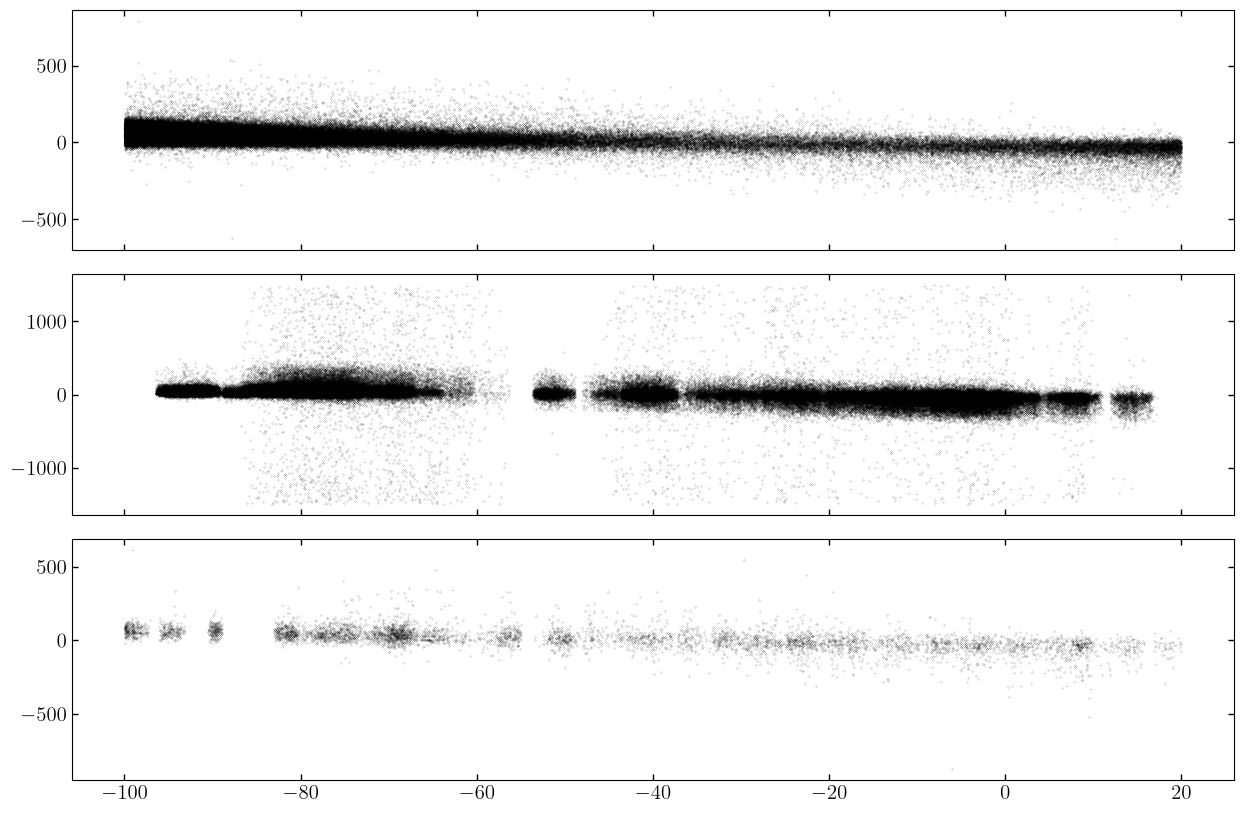

In [ ]:
fig, [ax1, ax2, ax3] = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
ax1.scatter(merged['phi1'], merged['rv_gaia'], s=0.01)
ax2.scatter(merged['phi1'], merged['rv_desi'], s=0.01)
ax3.scatter(merged['phi1'], merged['rv_apogee'], s=0.01)
plt.show()

In [437]:
merged['radial_velocity'] = np.nan
merged['radial_velocity_error'] = np.nan

In [438]:
merged['ra'][np.isnan(merged['ra'])] = merged['ra_ps1'][np.isnan(merged['ra'])]
merged['dec'][np.isnan(merged['dec'])] = merged['dec_ps1'][np.isnan(merged['dec'])]
merged.remove_column('ra_ps1')
merged.remove_column('dec_ps1')

### Fixing the DESI Offset as a function of $\phi_1$

9602


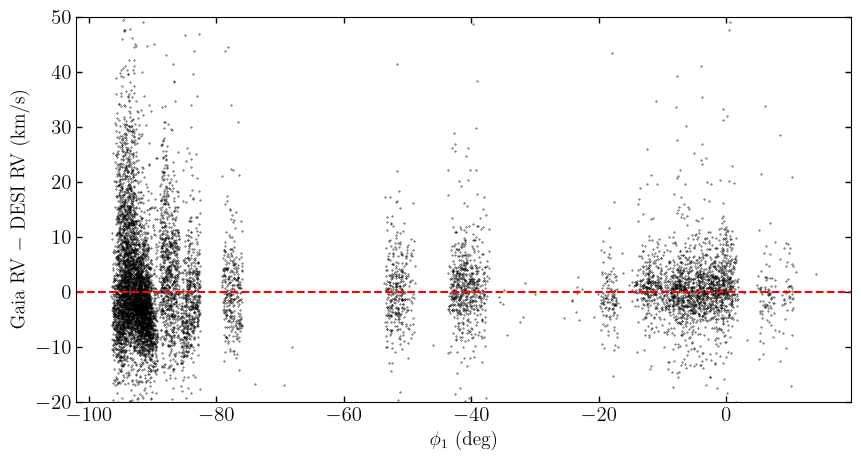

In [491]:
desi_comp = merged[(~np.isnan(merged['rv_desi']) & ((~np.isnan(merged['rv_gaia'])) | (~np.isnan(merged['rv_apogee']))))]
print(len(desi_comp))
plt.figure(figsize=(10, 5))
desi_rv_array = desi_comp['rv_desi']
other_rv_array = desi_comp['rv_gaia']
other_rv_array[np.isnan(desi_comp['rv_gaia'])] = desi_comp['rv_apogee'][np.isnan(desi_comp['rv_gaia'])]
plt.scatter(desi_comp['phi1'], other_rv_array - desi_rv_array, s=0.1)
plt.gca().axhline(0, color='r', linestyle='--')
plt.ylim(-20, 50)
plt.xlabel(r'$\phi_1$ (deg)')
plt.ylabel(r'Gaia RV $-$ DESI RV (km/s)')
plt.show()

In [487]:
binned_offset, bin_edges, _ = scipy.stats.binned_statistic(desi_comp['phi1'], other_rv_array - desi_rv_array, 
                                             statistic='median', bins=48, range=[-100, 20])
binned_count, bin_edges, _ = scipy.stats.binned_statistic(desi_comp['phi1'], other_rv_array - desi_rv_array, 
                                             statistic='count', bins=48, range=[-100, 20])
binned_offset[binned_count < 10] = np.nan
bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

offset_spl = scipy.interpolate.UnivariateSpline(bin_centers[~np.isnan(binned_offset)], 
                                                binned_offset[~np.isnan(binned_offset)], s=None)
phi1_values = np.arange(-100, 20, 0.1)

In [488]:
offset_spl(-50)

array(4.39579234)

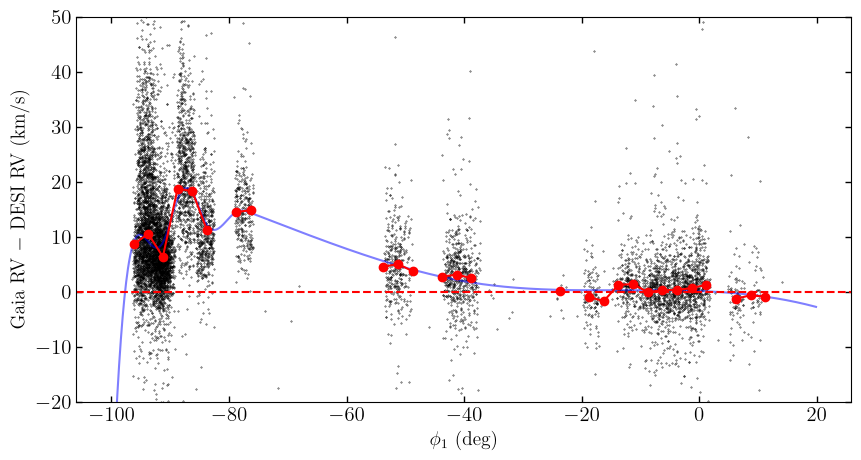

In [489]:
plt.figure(figsize=(10, 5))
plt.plot(phi1_values, offset_spl(phi1_values), color='b', alpha=0.5)
plt.plot(bin_edges[:-1] + np.diff(bin_edges)/2, binned_offset, marker='o', color='r')
plt.scatter(desi_comp['phi1'], other_rv_array - desi_rv_array, s=0.1)
plt.gca().axhline(0, color='r', linestyle='--')
plt.ylim(-20, 50)
plt.xlabel(r'$\phi_1$ (deg)')
plt.ylabel(r'Gaia RV $-$ DESI RV (km/s)')
plt.show()

In [ ]:
#apply the correction to the DESI radial velocities based on the spline fit to the offsets
merged['rv_desi'] = merged['rv_desi'] + offset_spl(merged['phi1'])

In [492]:
# Edit this list if your table has a different set of surveys/columns.
SURVEYS = ["gaia", "apogee", "desi"]
 
# Optional: zero-point corrections in km/s, subtracted from each survey's RV
# before combining (rv_corrected = rv_raw - OFFSETS[survey]). Leave at 0.0
# until you have vetted values for your specific survey data releases.
OFFSETS = {s: 0.0 for s in SURVEYS}

def combine_radial_velocities(table: Table, surveys=SURVEYS, offsets=OFFSETS) -> Table:
    """
    Returns table with three new columns added: 'radial_velocity',
    'radial_velocity_error' (km/s, as astropy Quantity columns), and
    'radial_velocity_n_surveys' -- the inverse-variance weighted combination
    of the per-survey rv_<survey> / rv_error_<survey> columns.
 
    Works with plain float columns, Quantity columns (any speed unit --
    converted to km/s), and masked columns.
    """
    rv_cols = [f"rv_{s}" for s in surveys]
    err_cols = [f"rv_error_{s}" for s in surveys]
 
    for c in rv_cols + err_cols:
        if c not in table.colnames:
            raise KeyError(f"Expected column '{c}' not found in table.")
 
    n = len(table)
    weighted_rv_sum = np.zeros(n)
    weight_sum = np.zeros(n)
 
    for s in surveys:
        rv = table[f"rv_{s}"].flatten() - offsets[s]
        err = table[f"rv_error_{s}"].flatten()
 
        valid = np.isfinite(rv) & np.isfinite(err) & (err > 0)
 
        weight = np.zeros(n)
        weight[valid] = 1.0 / err[valid] ** 2
 
        weighted_rv_sum += np.where(valid, rv * weight, 0.0)
        weight_sum += weight
 
    with np.errstate(divide="ignore", invalid="ignore"):
        combined_rv = np.where(weight_sum > 0, weighted_rv_sum / weight_sum, np.nan)
        combined_err = np.where(weight_sum > 0, 1.0 / np.sqrt(weight_sum), np.nan)
 
    table = table.copy()
    table["radial_velocity"] = combined_rv * (u.km / u.s)
    table["radial_velocity_error"] = combined_err * (u.km / u.s)
    return table

In [493]:
combined_tbl = combine_radial_velocities(merged)

In [494]:
combined_tbl

ra,dec,parallax,pmra,pmdec,pmra_error,pmdec_error,rv_gaia,rv_error_gaia,phot_g_mean_mag,phot_g_mean_flux_over_error,phot_bp_mean_mag,phot_bp_mean_flux_over_error,phot_rp_mean_mag,phot_rp_mean_flux_over_error,ruwe,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phi1,phi2,pm_phi1_cosphi2_unrefl,pm_phi2_unrefl,pm1_error,pm2_error,gaia_source_id,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,gMeanKronMag,rMeanKronMag,iMeanKronMag,zMeanKronMag,yMeanKronMag,gMeanKronMagErr,rMeanKronMagErr,iMeanKronMagErr,zMeanKronMagErr,yMeanKronMagErr,rv_desi,rv_error_desi,rv_apogee,rv_error_apogee,radial_velocity,radial_velocity_error
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,km / s,km / s
float64,float64,float64,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float64,float64,float64,float64,float64,int64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float32,float32,float64,float64
239.86551085372835,60.90659038867291,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,-1,41,8,18,9,6,0,21.306299209594727,21.141000747680664,21.058900833129883,21.02739906311035,-999.0,0.049199000000953674,0.03367000073194504,0.06727500259876251,0.06483300030231476,-999.0,21.436100006103516,21.30120086669922,21.259199142456055,21.24959945678711,-999.0,0.09831800311803818,0.10792399942874908,0.10682900249958038,0.08207199722528458,-999.0,nan,nan,nan,nan,nan,nan
241.26166636078318,60.88914325442862,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,-1,44,5,14,19,6,0,21.564699172973633,21.200300216674805,20.99570083618164,20.807100296020508,-999.0,0.06841599941253662,0.031776998192071915,0.026348000392317772,0.055904000997543335,-999.0,21.614900588989258,21.25189971923828,21.110000610351562,20.934099197387695,-999.0,0.15903399884700775,0.08742199838161469,0.058171000331640244,0.09593699872493744,-999.0,nan,nan,nan,nan,nan,nan
240.56978437252195,61.140837520876644,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,-1,45,1,1,20,13,10,21.705699920654297,21.492900848388672,20.442699432373047,19.722400665283203,19.379600524902344,0.19486699998378754,0.1425980031490326,0.025250999256968498,0.021904999390244484,0.051339998841285706,21.740400314331055,21.25819969177246,20.538799285888672,19.800500869750977,19.40180015563965,0.2971169948577881,0.18334800004959106,0.057530999183654785,0.048344001173973083,0.09813199937343597,nan,nan,nan,nan,nan,nan
240.08673614404734,61.247642350531244,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,-1,17,1,5,3,5,3,21.429500579833984,20.861499786376953,20.32469940185547,20.74679946899414,20.217100143432617,0.1188030019402504,0.022182999178767204,0.03176100179553032,0.05411199852824211,0.11190800368785858,20.937599182128906,20.2947998046875,20.28820037841797,19.933700561523438,19.65169906616211,0.15353399515151978,0.12200099974870682,0.08407100290060043,0.12210799753665924,0.3081969916820526,nan,nan,nan,nan,nan,nan
239.02207216118634,61.334697045598766,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,-1,58,3,20,11,12,12,20.7052001953125,19.97410011291504,19.662799835205078,19.531299591064453,19.272600173950195,0.018823999911546707,0.014201999641954899,0.008005999960005283,0.019598999992012978,0.07225

In [495]:
# dust extinction
from pyia import GaiaData
from dustmaps.sfd import SFDQuery

g = GaiaData(combined_tbl)
g.get_ebv(dustmaps_cls=SFDQuery)

coeffs = {
    'g': 3.172,
    'r': 2.271, 
    'i': 1.682, 
    'z': 1.322, 
    'y': 1.087
}

ebv = g.get_ebv(dustmaps_cls=SFDQuery)
Avals = {k: coeffs[k] * ebv for k in coeffs}

for k in coeffs:
    g.data[f'{k}_0'] = g[f'{k}MeanPSFMag'] - Avals[k]

In [496]:
#get stream coordinates for data
stream_frame = gc.GD1Koposov10()
c_gd1 = g.get_skycoord(distance=False).transform_to(stream_frame) # uses reference epoch of latest Gaia release by default
g['phi1'] = getattr(c_gd1, "phi1")
g['phi2'] = getattr(c_gd1, "phi2")
g['pm_phi1_cosphi2_unrefl'] = getattr(c_gd1, "pm_phi1_cosphi2")
g['pm_phi2_unrefl'] = getattr(c_gd1, "pm_phi2")

pm_cov, _ = g.get_cov(coords=['pmra', 'pmdec'])
c = coord.SkyCoord(ra = g['ra'], dec=g['dec'])
gd1_coord_pm_cov = gc.transform_pm_cov(c=c, cov=pm_cov, to_frame=stream_frame)

g['pm1_error'] = np.sqrt(gd1_coord_pm_cov[:,0,0]) * u.mas/u.yr
g['pm2_error'] = np.sqrt(gd1_coord_pm_cov[:,1,1]) * u.mas/u.yr

In [497]:
final_tbl = g.data

In [498]:
final_tbl.write('/Users/Tavangar/Work/gd1-dr3/data/all-gd1-combined.fits', overwrite =True)

In [ ]:
final_tbl

ra,dec,parallax,pmra,pmdec,pmra_error,pmdec_error,rv_gaia,rv_error_gaia,phot_g_mean_mag,phot_g_mean_flux_over_error,phot_bp_mean_mag,phot_bp_mean_flux_over_error,phot_rp_mean_mag,phot_rp_mean_flux_over_error,ruwe,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phi1,phi2,pm_phi1_cosphi2_unrefl,pm_phi2_unrefl,pm1_error,pm2_error,gaia_source_id,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,gMeanKronMag,rMeanKronMag,iMeanKronMag,zMeanKronMag,yMeanKronMag,gMeanKronMagErr,rMeanKronMagErr,iMeanKronMagErr,zMeanKronMagErr,yMeanKronMagErr,rv_desi,rv_error_desi,rv_apogee,rv_error_apogee,radial_velocity,radial_velocity_error,g_0,r_0,i_0,z_0,y_0
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,km / s,km / s,,,,,
float64,float64,float64,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float64,float64,float64,float64,float64,int64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float32,float32,float64,float64,float64,float64,float64,float64,float64
239.86551085372835,60.90659038867291,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,19.354992886878474,2.955380504429113,nan,nan,nan,nan,-1,41,8,18,9,6,0,21.306299209594727,21.141000747680664,21.058900833129883,21.02739906311035,-999.0,0.049199000000953674,0.03367000073194504,0.06727500259876251,0.06483300030231476,-999.0,21.436100006103516,21.30120086669922,21.259199142456055,21.24959945678711,-999.0,0.09831800311803818,0.10792399942874908,0.10682900249958038,0.08207199722528458,-999.0,nan,nan,nan,nan,nan,nan,21.272011198103428,21.116452176123857,21.040719106793404,21.01310878805816,-999.0117500219494
241.26166636078318,60.88914325442862,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,19.99044455377377,3.1977734366671724,nan,nan,nan,nan,-1,44,5,14,19,6,0,21.564699172973633,21.200300216674805,20.99570083618164,20.807100296020508,-999.0,0.06841599941253662,0.031776998192071915,0.026348000392317772,0.055904000997543335,-999.0,21.614900588989258,21.25189971923828,21.110000610351562,20.934099197387695,-999.0,0.15903399884700775,0.08742199838161469,0.058171000331640244,0.09593699872493744,-999.0,nan,nan,nan,nan,nan,nan,21.520237237215042,21.168467599898577,20.972124233841896,20.788569815456867,-999.0152364838868
240.56978437252195,61.140837520876644,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,19.583396370861408,3.300724458896167,nan,nan,nan,nan,-1,45,1,1,20,13,10,21.705699920654297,21.492900848388672,20.442699432373047,19.722400665283203,19.379600524902344,0.19486699998378754,0.1425980031490326,0.025250999256968498,0.021904999390244484,0.051339998841285706,21.740400314331055,21.25819969177246,20.538799285888672,19.800500869750977,19.40180015563965,0.2971169948577881,0.18334800004959106,0.057530999183654785,0.048344001173973083,0.09813199937343597,nan,nan,nan,nan,nan,nan,21.671568982303143,21.468464732170105,20.42460099607706,19.708175853826106,19.367904329672456
240.08673614404734,61.247642350531244,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,19.32711928772602,3.311735186269388,nan,nan,nan,nan,-1,17,1,5,3,5,3,21.429500579833984,20.861499786376953,20.32469940185547,20.74679946899414,20.217100143432617,0.1188030019402504,0.022182999178767204,0.03176100179553032,0.05411199852824211,0.11190800368785858,20.937599182128906,20.2947998046875,20.28820037841797,19.933700561523438,19.65169906616211,0.153533995151519

: 

Possible Data Quality Cuts:

- Note that I did not account for binaries when doing the radial velocity combination within a single survey. This could be done for every star with more than two targets by making sure that the radial velocities are consistent with one another
- Stars that are in Gaia but not in PS1